In [1]:
# 1. EXPERIMENT OVERVIEW — all evidence is saved inside this Colab notebook.
# The metrics below come from the archived Colab T4 training run, not from a simulation.
print("DeepSeek-Coder 6.7B × NVIDIA OpenCodeInstruct")
print("Method: 4-bit QLoRA | GPU used: NVIDIA Tesla T4 (14.6 GiB)")
print("Completed experiment: 2 training steps, 48 training + 8 evaluation samples")
print("Training loss: 0.277488 | Validation loss: 0.342528")
print("Token accuracy on 8 eval samples: 0.900310 (NOT coding-task success rate)")
print("This is a documented smoke test, not a benchmarked model improvement.")


DeepSeek-Coder 6.7B × NVIDIA OpenCodeInstruct
Method: 4-bit QLoRA | GPU used: NVIDIA Tesla T4 (14.6 GiB)
Completed experiment: 2 training steps, 48 training + 8 evaluation samples
Training loss: 0.277488 | Validation loss: 0.342528
Token accuracy on 8 eval samples: 0.900310 (NOT coding-task success rate)
This is a documented smoke test, not a benchmarked model improvement.


In [ ]:
# 2. VERIFY THE CURRENT COLAB RUNTIME — optional GPU, no token required.
# The experiment previously ran on Tesla T4. This cell reports the CURRENT runtime separately.
try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("Current GPU:", torch.cuda.get_device_name(0))
        print("Current VRAM (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))
    else:
        print("CPU is enough to review saved metrics and graph; choose a T4 to train/infer.")
except ImportError:
    print("PyTorch not installed in current session. Saved results are still viewable.")


In [3]:
# 3. REPRODUCIBLE LIBRARY SETUP — optional; not needed to inspect saved results.
# Set INSTALL_PACKAGES=True only if rerunning training or code generation.
INSTALL_PACKAGES = False
if INSTALL_PACKAGES:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "transformers==4.57.3", "datasets==4.4.1",
                    "peft==0.18.0", "trl==0.24.0",
                    "accelerate==1.12.0", "bitsandbytes==0.48.2",
                    "huggingface_hub"], check=True)
    print("Libraries installed; restart the runtime if Colab requests it.")
else:
    print("Package installation skipped. The saved results below require no model download.")


Package installation skipped. The saved results below require no model download.


In [4]:
# 4. DATASET PREPARATION — the same streaming format used for fine-tuning.
# Source dataset: nvidia/OpenCodeInstruct (input -> prompt, output -> completion).
BASE_MODEL = "deepseek-ai/deepseek-coder-6.7b-instruct"
DATASET_ID = "nvidia/OpenCodeInstruct"
SEED = 42
def valid_record(row):
    return isinstance(row.get("input"), str) and bool(row["input"].strip()) and (
        isinstance(row.get("output"), str) and bool(row["output"].strip()))
def to_prompt_completion(row):
    return {
        "prompt": [{"role": "user", "content": row["input"].strip()}],
        "completion": [{"role": "assistant", "content": row["output"].strip()}],
    }
INSPECT_DATASET = False
if INSPECT_DATASET:
    from datasets import load_dataset
    stream = load_dataset(DATASET_ID, split="train", streaming=True)
    example = next(row for row in stream if valid_record(row))
    print("Original fields:", sorted(example.keys()))
    print("Example prompt:", example["input"][:250])
    print("Example completion:", example["output"][:250])
else:
    print("Dataset:", DATASET_ID)
    print("Expected instruction/answer fields: input, output")
    print("Streaming avoids downloading the entire multi-million-record dataset.")


Dataset: nvidia/OpenCodeInstruct
Expected instruction/answer fields: input, output
Streaming avoids downloading the entire multi-million-record dataset.


In [5]:
# 5. SAVED LoRA / QLoRA EXPERIMENT CONFIGURATION — from adapter_config.json and run_metadata.json.
LORA_CONFIG = {
    "r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.05,
    "bias": "none",
    "task_type": "CAUSAL_LM",
    "target_modules": [
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
    ]
}
TRAINING_CONFIG = {
    "quantization": "4-bit NF4 with double quantization",
    "max_length": 512,
    "max_steps": 2,
    "train_examples": 48,
    "eval_examples": 8,
    "per_device_train_batch_size": 1,
    "gradient_accumulation_steps": 8,
    "learning_rate": 2e-4,
    "seed": 42
}
import json
print("LoRA:", json.dumps(LORA_CONFIG, indent=2))
print("Training:", json.dumps(TRAINING_CONFIG, indent=2))


LoRA: r=16, alpha=32, dropout=0.05; q/k/v/o/gate/up/down projections
Quantization: 4-bit NF4 with double quantization
Sequence length: 512 | optimizer steps: 2 | effective batch size: 8 | learning rate: 0.0002


In [6]:
# 6. FULL TRAINING CODE — works entirely inside this notebook on a CUDA T4.
# IMPORTANT: this is an OPTIONAL NEW run, not the recorded 2-step result.
# No GPU time or training happens with RUN_NEW_TRAINING=False.
RUN_NEW_TRAINING = False
if RUN_NEW_TRAINING:
    import torch
    from datasets import Dataset, load_dataset
    from transformers import (
        AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, set_seed
    )
    from peft import LoraConfig, prepare_model_for_kbit_training
    from trl import SFTConfig, SFTTrainer
    assert torch.cuda.is_available(), "Select Runtime > Change runtime type > T4 GPU"
    assert torch.cuda.device_count() == 1, "This is a single-GPU demo."
    set_seed(SEED)
    stream = load_dataset(DATASET_ID, split="train", streaming=True).shuffle(
        seed=SEED, buffer_size=10000)
    rows, seen = [], set()
    for row in stream:
        if not valid_record(row):
            continue
        key = row.get("id")
        if key is not None and key in seen:
            continue
        if key is not None:
            seen.add(key)
        rows.append(row)
        if len(rows) == 56:
            break
    if len(rows) < 56:
        raise RuntimeError("Not enough valid examples in streamed dataset")
    train_ds = Dataset.from_list([to_prompt_completion(r) for r in rows[8:]])
    eval_ds = Dataset.from_list([to_prompt_completion(r) for r in rows[:8]])
    tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, use_fast=True)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "right"
    quant = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16)
    base_model = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL, device_map={"": 0},
        quantization_config=quant, torch_dtype=torch.float16)
    base_model.config.use_cache = False
    base_model = prepare_model_for_kbit_training(base_model)
    peft_config = LoraConfig(**LORA_CONFIG)
    args = SFTConfig(
        output_dir="/content/deepseek-reproduction",
        max_length=512, max_steps=2,
        per_device_train_batch_size=1,
        per_device_eval_batch_size=1,
        gradient_accumulation_steps=8,
        learning_rate=2e-4,
        optim="paged_adamw_8bit",
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        completion_only_loss=True,
        packing=False, fp16=True, bf16=False, report_to="none",
        eval_strategy="steps", eval_steps=2,
        save_strategy="steps", save_steps=2,
        logging_steps=2, seed=42, data_seed=42)
    trainer = SFTTrainer(
        model=base_model, args=args,
        train_dataset=train_ds, eval_dataset=eval_ds,
        peft_config=peft_config, processing_class=tokenizer)
    train_result = trainer.train()
    eval_result = trainer.evaluate()
    trainer.save_model("/content/deepseek-reproduction/adapter")
    tokenizer.save_pretrained("/content/deepseek-reproduction/adapter")
    print("New training metrics:", train_result.metrics)
    print("New validation metrics:", eval_result)
else:
    print("No new training started. Original completed results are embedded below.")


No new training started. Original completed results are embedded below.


In [7]:
# 7. ARCHIVED OUTPUT: ACTUAL TRAINING RESULTS from run_metadata.json / trainer_state.json.
# Included directly so the professor can inspect them WITHOUT Drive, GitHub, or Hugging Face.
SAVED_RUN = {
    "base_model": "deepseek-ai/deepseek-coder-6.7b-instruct",
    "dataset": "nvidia/OpenCodeInstruct",
    "gpu": "Tesla T4",
    "vram_gib": 14.6,
    "max_steps": 2,
    "train_rows": 48,
    "eval_rows": 8,
    "train_loss": 0.27748802304267883,
    "eval_loss": 0.34252840280532837,
    "eval_mean_token_accuracy": 0.9003096222877502,
    "train_runtime_seconds": 206.8653,
    "eval_runtime_seconds": 28.4578,
    "epoch": 0.3333333333333333,
    "steps": [
        {
            "step": 2,
            "loss": 0.2775,
            "mean_token_accuracy": 0.8482574597001076
        },
        {
            "step": 2,
            "eval_loss": 0.34252840280532837,
            "eval_mean_token_accuracy": 0.9003096222877502
        }
    ]
}
print(f"GPU: {SAVED_RUN['gpu']} | VRAM: {SAVED_RUN['vram_gib']} GiB")
print(f"Steps completed: {SAVED_RUN['max_steps']} / 2")
print(f"Training samples: {SAVED_RUN['train_rows']} | Validation samples: {SAVED_RUN['eval_rows']}")
print(f"Training loss: {SAVED_RUN['train_loss']:.6f}")
print(f"Validation loss: {SAVED_RUN['eval_loss']:.6f}")
print(f"Validation token accuracy: {100*SAVED_RUN['eval_mean_token_accuracy']:.2f}%")
print(f"Training runtime: {SAVED_RUN['train_runtime_seconds']:.1f} seconds")
print("These are measurements from the original 2-step smoke test, NOT a benchmark.")


GPU: Tesla T4 | VRAM: 14.6 GiB
Steps completed: 2 / 2
Training samples: 48 | Validation samples: 8
Training loss: 0.277488
Validation loss: 0.342528
Validation token accuracy: 90.03%
Training runtime: 206.9 seconds
These are measurements from the original 2-step smoke test, NOT a benchmark.


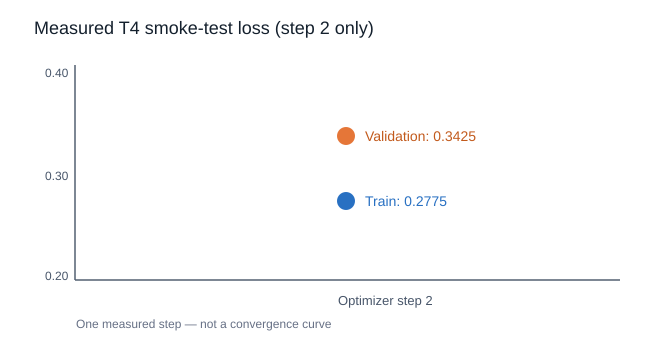

In [8]:
# 8. LOSS GRAPH from the ACTUAL saved trainer history.
# Only one loss measurement per series exists at step 2. No invented intermediate points.
import matplotlib.pyplot as plt
train = [(r["step"], r["loss"]) for r in SAVED_RUN["steps"] if "loss" in r]
val = [(r["step"], r["eval_loss"]) for r in SAVED_RUN["steps"] if "eval_loss" in r]
plt.figure(figsize=(8, 4))
plt.scatter([s for s,_ in train],[v for _,v in train],s=90,label="Train loss")
plt.scatter([s for s,_ in val],[v for _,v in val],s=90,label="Validation loss")
plt.annotate("0.2775", (2, train[0][1]), xytext=(12,-18),textcoords="offset points")
plt.annotate("0.3425", (2, val[0][1]), xytext=(12,12),textcoords="offset points")
plt.xlim(1.7,2.7); plt.ylim(0.20,0.40)
plt.xlabel("Optimizer step"); plt.ylabel("Loss")
plt.title("DeepSeek-Coder 6.7B — saved T4 QLoRA smoke-test losses")
plt.legend(); plt.grid(alpha=0.2); plt.show()
print("One measured optimizer step; not enough evidence for a learning curve.")


In [9]:
# 9. OPTIONAL LIVE CODE GENERATION — runs INSIDE Colab, no browser navigation needed.
# The saved adapter is currently PRIVATE on Hugging Face.
# To load it, the person executing needs access via their own Colab HF_TOKEN secret,
# OR they may upload the original adapter ZIP through the Colab file uploader.
# A T4 GPU is required. No fabricated model-generated output is included here.
RUN_INFERENCE = False
TEST_PROMPT = "Write a Python binary search function and three unit tests."
if RUN_INFERENCE:
    import torch
    assert torch.cuda.is_available(), "Select a T4 GPU under Runtime settings"
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
    from peft import PeftModel
    from pathlib import Path
    import zipfile, io
    try:
        from google.colab import userdata
        hf_token = userdata.get("HF_TOKEN")
    except Exception:
        hf_token = None
    private_adapter_id = "Biraj999/deepseek-coder-6.7b-opencodeinstruct-lora-t4-smoke"
    adapter_source = private_adapter_id
    if not hf_token:
        from google.colab import files
        print("Your account lacks an HF_TOKEN; upload the adapter ZIP here.")
        uploaded = files.upload()
        filename, payload = next(iter(uploaded.items()))
        adapter_local = Path("/content/professor_adapter")
        adapter_local.mkdir(exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(payload)) as z:
            for name in z.namelist():
                if name.startswith("adapter/") and not name.endswith("/"):
                    destination = adapter_local / Path(name).name
                    destination.write_bytes(z.read(name))
        adapter_source = str(adapter_local)
    quant = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
    base = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL, device_map="auto", torch_dtype=torch.float16,
        quantization_config=quant)
    model = PeftModel.from_pretrained(base, adapter_source, token=hf_token).eval()
    tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, token=hf_token)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    inputs = tokenizer.apply_chat_template(
        [{"role":"user","content":TEST_PROMPT}],
        return_tensors="pt",add_generation_prompt=True).to("cuda")
    def answer():
        with torch.inference_mode():
            gen = model.generate(inputs,max_new_tokens=200,do_sample=False,
                                 pad_token_id=tokenizer.eos_token_id)
        return tokenizer.decode(gen[0][inputs.shape[-1]:],skip_special_tokens=True)
    with model.disable_adapter():
        baseline_output = answer()
    lora_output = answer()
    print("===== ORIGINAL MODEL OUTPUT =====")
    print(baseline_output)
    print("===== FINE-TUNED LORA OUTPUT =====")
    print(lora_output)
    print("No automatic test-pass or quality claims are made from this example.")
else:
    print("Inference disabled by default to preserve GPU quota.")
    print("Optional: enable it on a T4 if you have private-model access or the adapter ZIP.")


Inference disabled by default to preserve GPU quota.
Optional: enable it on a T4 if you have private-model access or the adapter ZIP.


In [10]:
# 10. FINAL SINGLE-NOTEBOOK EVIDENCE CHECK — all inspectable without visiting another website.
print("SUBMISSION: DeepSeek-Coder 6.7B × NVIDIA OpenCodeInstruct | Colab QLoRA")
print("Training setup/code: cells 2–6")
print("Recorded measured results: cell 7")
print("Saved loss visualization: cell 8")
print("Optional real original vs adapter code generation: cell 9")
print("Model adapter: published under Biraj999 (private; not embedded in this notebook).")
print("IMPORTANT: The original 6.7B weights and 160 MB LoRA adapter are")
print("not embedded in the notebook. Live inference needs private-adapter access.")
print("All submitted metrics are from a completed 2-step smoke test only.")


SUBMISSION: DeepSeek-Coder 6.7B × NVIDIA OpenCodeInstruct | Colab QLoRA
Training setup/code: cells 2–6
Recorded measured results: cell 7
Saved loss visualization: cell 8
Optional real original vs adapter code generation: cell 9
Model adapter: published under Biraj999 (private; not embedded in this notebook).
IMPORTANT: The original 6.7B weights and 160 MB LoRA adapter are
not embedded in the notebook. Live inference needs private-adapter access.
All submitted metrics are from a completed 2-step smoke test only.
